In [1]:
!pip install torch torchvision matplotlib

In [1]:
import copy
import math
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

CFG = {
    "epochs": 10,
    "lr": 1e-3,
    "batch_size": 128,
    "n_val": 5000,
    "augment": False,
    "seed": 42,
}

torch.manual_seed(CFG["seed"])

device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("Urządzenie:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Urządzenie: cuda
GPU: Tesla T4


In [2]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

tf_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

tf_train = transforms.Compose(
    ([transforms.RandomCrop(32, padding=4),
      transforms.RandomHorizontalFlip()] if CFG["augment"] else [])
    + [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

train_full_aug = torchvision.datasets.CIFAR10(
    "./data", train=True, download=True, transform=tf_train
)

train_full_eval = torchvision.datasets.CIFAR10(
    "./data", train=True, download=True, transform=tf_eval
)

test_ds = torchvision.datasets.CIFAR10(
    "./data", train=False, download=True, transform=tf_eval
)

classes = train_full_eval.classes

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(train_full_eval), generator=g).tolist()

val_idx = perm[:CFG["n_val"]]
train_idx = perm[CFG["n_val"]:]

train_ds = Subset(train_full_aug, train_idx)
val_ds = Subset(train_full_eval, val_idx)

train_dl = DataLoader(
    train_ds,
    batch_size=CFG["batch_size"],
    shuffle=True,
    num_workers=2
)

val_dl = DataLoader(
    val_ds,
    batch_size=256,
    shuffle=False,
    num_workers=2
)

test_dl = DataLoader(
    test_ds,
    batch_size=256,
    shuffle=False,
    num_workers=2
)

print("Klasy:", classes)
print(f"Trening: {len(train_ds)} | Walidacja: {len(val_ds)} | Test: {len(test_ds)}")

100%|██████████| 170M/170M [39:02<00:00, 72.8kB/s]


Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | Walidacja: 5000 | Test: 10000


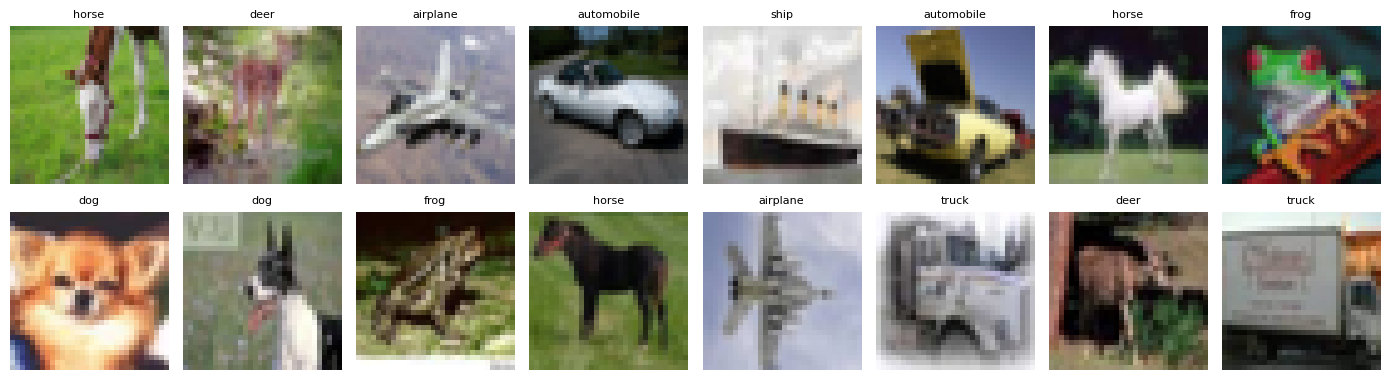

In [3]:
# podgląd przykładowych obrazów
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)

def denorm(img):
    return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_dl))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img))
    ax.set_title(classes[lb], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# modele MLP i SimpleCNN
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]),
            nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]),
            nn.ReLU(),
            nn.Linear(hidden[1], n_classes)
        )

    def forward(self, x):
        return self.net(x)


def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),

        nn.Conv2d(cout, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),

        nn.MaxPool2d(2)
    )


class SimpleCNN(nn.Module):
    def __init__(self, c1=32, c2=64, n_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            block(3, c1),
            block(c1, c2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c2 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


mlp_tmp = MLP()
cnn_tmp = SimpleCNN()

print("MLP:", count_params(mlp_tmp))
print("CNN część splotowa:", count_params(cnn_tmp.features))
print("CNN głowica:", count_params(cnn_tmp.classifier))
print("CNN razem:", count_params(cnn_tmp))

MLP: 1707274
CNN część splotowa: 65952
CNN głowica: 1051402
CNN razem: 1117354


In [5]:
# testy kontrolne przed treningiem

# Test 1: sprawdzenie kształtów

x = torch.randn(4, 3, 32, 32)

for name, layer in cnn_tmp.features.named_children():
    x = layer(x)
    print("Blok", name, tuple(x.shape))

print("Logity:", tuple(cnn_tmp.classifier(x).shape))


# Test 2: strata początkowa

crit = nn.CrossEntropyLoss()

xb, yb = next(iter(train_dl))

for name, model in [("MLP", MLP()), ("CNN", SimpleCNN())]:
    model = model.to(device).eval()

    with torch.no_grad():
        loss = crit(model(xb.to(device)), yb.to(device))

    print(name, "strata na starcie:", loss.item())
    print("Oczekiwane około:", math.log(10))


# Test 3: przeuczenie jednej paczki

m = SimpleCNN().to(device)
opt = torch.optim.Adam(m.parameters(), lr=1e-3)

xb, yb = next(iter(train_dl))
xb, yb = xb[:32].to(device), yb[:32].to(device)

m.train()

for step in range(101):
    opt.zero_grad()
    loss = crit(m(xb), yb)
    loss.backward()
    opt.step()

    if step % 25 == 0:
        print(f"Krok {step:3d} | strata {loss.item():.4f}")

Blok 0 (4, 32, 16, 16)
Blok 1 (4, 64, 8, 8)
Logity: (4, 10)
MLP strata na starcie: 2.308840274810791
Oczekiwane około: 2.302585092994046
CNN strata na starcie: 2.3033058643341064
Oczekiwane około: 2.302585092994046
Krok   0 | strata 2.4000
Krok  25 | strata 0.0026
Krok  50 | strata 0.0004
Krok  75 | strata 0.0005
Krok 100 | strata 0.0001


In [7]:
# funkcje treningu i ewaluacji
def sync():
    if device == "cuda":
        torch.cuda.synchronize()


def train_one_epoch(model, dl, opt, crit):
    model.train()
    s = n = 0

    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)

        opt.zero_grad()
        loss = crit(model(xb), yb)
        loss.backward()
        opt.step()

        s += loss.item() * yb.size(0)
        n += yb.size(0)

    return s / n


@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval()
    s = c = n = 0

    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)

        out = model(xb)

        s += crit(out, yb).item() * yb.size(0)
        c += (out.argmax(1) == yb).sum().item()
        n += yb.size(0)

    return s / n, c / n


train_eval_dl = DataLoader(
    Subset(train_full_eval, train_idx),
    batch_size=256,
    shuffle=False,
    num_workers=2
)


def fit(model, cfg=CFG):
    torch.manual_seed(cfg["seed"])

    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

    hist = {
        k: [] for k in
        ["train_loss", "train_acc", "val_loss", "val_acc"]
    }

    best = {
        "val_acc": -1.0,
        "epoch": 0,
        "state": None
    }

    train_time = eval_time = 0.0

    for epoch in range(1, cfg["epochs"] + 1):

        sync()
        t0 = time.time()

        train_one_epoch(model, train_dl, opt, crit)

        sync()
        t1 = time.time()

        tr_loss, tr_acc = evaluate(model, train_eval_dl, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)

        sync()
        t2 = time.time()

        train_time += t1 - t0
        eval_time += t2 - t1

        for k, v in zip(
            hist,
            [tr_loss, tr_acc, va_loss, va_acc]
        ):
            hist[k].append(v)

        if va_acc > best["val_acc"]:
            best = {
                "val_acc": va_acc,
                "epoch": epoch,
                "state": copy.deepcopy(model.state_dict())
            }

        print(
            f"Epoka {epoch:2d} | "
            f"strata tr {tr_loss:.3f} val {va_loss:.3f} | "
            f"acc tr {tr_acc*100:6.2f}% "
            f"val {va_acc*100:6.2f}%"
        )

    model.load_state_dict(best["state"])

    return {
        "model": model,
        "hist": hist,
        "best": best,
        "train_time": train_time,
        "eval_time": eval_time
    }

In [8]:
# trening obu moedli
print("=== MLP ===")
res_mlp = fit(MLP())

print("\n=== SimpleCNN ===")
res_cnn = fit(SimpleCNN())

=== MLP ===
Epoka  1 | strata tr 1.454 val 1.528 | acc tr  48.67% val  46.16%
Epoka  2 | strata tr 1.332 val 1.468 | acc tr  52.97% val  48.82%
Epoka  3 | strata tr 1.202 val 1.386 | acc tr  57.79% val  51.30%
Epoka  4 | strata tr 1.131 val 1.404 | acc tr  59.86% val  51.22%
Epoka  5 | strata tr 1.043 val 1.385 | acc tr  63.02% val  51.96%
Epoka  6 | strata tr 0.949 val 1.396 | acc tr  66.64% val  52.52%
Epoka  7 | strata tr 0.871 val 1.428 | acc tr  69.29% val  53.02%
Epoka  8 | strata tr 0.823 val 1.472 | acc tr  70.93% val  52.84%
Epoka  9 | strata tr 0.738 val 1.525 | acc tr  74.05% val  53.40%
Epoka 10 | strata tr 0.671 val 1.554 | acc tr  76.43% val  52.88%

=== SimpleCNN ===
Epoka  1 | strata tr 1.001 val 1.013 | acc tr  64.09% val  63.86%
Epoka  2 | strata tr 0.837 val 0.895 | acc tr  70.46% val  68.46%
Epoka  3 | strata tr 0.706 val 0.785 | acc tr  74.90% val  73.08%
Epoka  4 | strata tr 0.586 val 0.707 | acc tr  79.09% val  75.02%
Epoka  5 | strata tr 0.521 val 0.685 | acc tr

In [9]:
# wyniki końcowe i porównanie modeli
crit = nn.CrossEntropyLoss()

rows = []

for name, r in [("MLP", res_mlp), ("CNN", res_cnn)]:
    model = r["model"]
    hist = r["hist"]
    best = r["best"]

    test_loss, test_acc = evaluate(model, test_dl, crit)

    i = best["epoch"] - 1

    train_acc = hist["train_acc"][i]
    val_acc = hist["val_acc"][i]

    gap = train_acc - val_acc

    rows.append([
        name,
        count_params(model),
        best["epoch"],
        train_acc,
        val_acc,
        gap,
        test_acc,
        r["train_time"]
    ])

print("PORÓWNANIE MODELI")
print("-" * 110)

print(
    f"{'Model':<8} {'Parametry':>12} {'Epoka':>7} "
    f"{'Train acc':>11} {'Val acc':>11} "
    f"{'Przerwa':>11} {'Test acc':>11} {'Czas [s]':>11}"
)

for name, p, ep, tr, va, gap, te, t in rows:
    print(
        f"{name:<8} {p:>12,} {ep:>7} "
        f"{tr*100:>10.2f}% {va*100:>10.2f}% "
        f"{gap*100:>10.2f}pp {te*100:>10.2f}% {t:>11.1f}"
    )

print("\nCNN część splotowa:", count_params(res_cnn["model"].features))
print("CNN głowica:", count_params(res_cnn["model"].classifier))
print("Klasyfikator losowy: 10.00%")
print("Czas uczenia nie obejmuje ewaluacji.")

PORÓWNANIE MODELI
--------------------------------------------------------------------------------------------------------------
Model       Parametry   Epoka   Train acc     Val acc     Przerwa    Test acc    Czas [s]
MLP         1,707,274       9      74.05%      53.40%      20.65pp      53.21%       101.8
CNN         1,117,354      10      90.70%      80.28%      10.42pp      79.45%       118.1

CNN część splotowa: 65952
CNN głowica: 1051402
Klasyfikator losowy: 10.00%
Czas uczenia nie obejmuje ewaluacji.


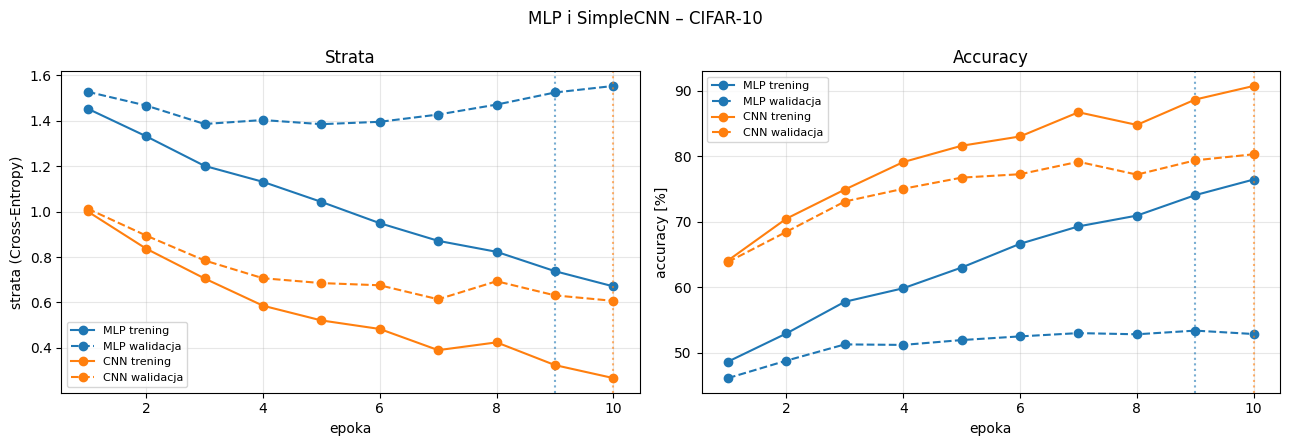

In [10]:
# krzywe uczenia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for name, r, color in [
    ("MLP", res_mlp, "tab:blue"),
    ("CNN", res_cnn, "tab:orange")
]:
    h = r["hist"]
    ep = range(1, len(h["train_loss"]) + 1)

    ax1.plot(
        ep, h["train_loss"], "-o",
        color=color, label=f"{name} trening"
    )

    ax1.plot(
        ep, h["val_loss"], "--o",
        color=color, label=f"{name} walidacja"
    )

    ax2.plot(
        ep, [a*100 for a in h["train_acc"]], "-o",
        color=color, label=f"{name} trening"
    )

    ax2.plot(
        ep, [a*100 for a in h["val_acc"]], "--o",
        color=color, label=f"{name} walidacja"
    )

    for ax in (ax1, ax2):
        ax.axvline(
            r["best"]["epoch"],
            color=color,
            ls=":",
            alpha=0.6
        )

ax1.set(
    xlabel="epoka",
    ylabel="strata (Cross-Entropy)",
    title="Strata"
)

ax2.set(
    xlabel="epoka",
    ylabel="accuracy [%]",
    title="Accuracy"
)

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle("MLP i SimpleCNN – CIFAR-10")
plt.tight_layout()
plt.show()